# Pruning Algorithm Test Suite

This notebook provides examples that **require pruning** to test the dead-end removal algorithm.
The improved `find_path` function naturally avoids some dead ends, so the standard random-network
pipeline may not always exercise the pruning logic.

Three approaches are used to create networks with guaranteed dead ends:

1. **Manual examples:** hand-crafted stick geometries with known dead-end branches
2. **Augmented networks:** load a previously generated network and add extra dead-end sticks
3. **Small-`a` random networks:** use shorter sticks to create denser intersection patterns

Each section runs the full pipeline: intersections → percolation paths → edge discovery →
pruning → impedance calculation, and compares before/after pruning.

---
## 1. Setup and Imports

In [1]:
import math
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Environment: Local
Utils path: <project_root>/utils
Files available: ['filtered_paths.py', 'pipeline_utils_src.py', 'utility_reset.py', 'admittance_checks.py', 'plotting_old.py', '.DS_Store', 'result_exporter.py', 'path_analysis.py', 'pdf_generator.py', 'self_loop_utils.py', 'plotting.py', 'path_pairs_of_lines vs  path_pairs_of_edges.txt', 'node_loop_test_runner.py', 'pruning.py', 'point_generator.py', '__pycache__', 'rebuild_experiments.py', 'edge_discovery.py', 'nextSteps.txt', 'region_checks.py', 'network_visualization.py', 'test_merge.py', 'laplacian_utils.py', 'intersection_utils.py', 'test_networks.py', 'impedance_calculator.py', 'self_loops.py', 'node_loop_visualization.py', 'loop_topology_utils.py', 'pipeline_utils.py', 'experiment_manager.py', 'boundary_utils.py']


In [2]:
import importlib
import point_generator as point_generator_module
#from point_generator import *
import result_exporter as result_exporter_module
#from result_exporter import *

importlib.reload(point_generator_module)
importlib.reload(result_exporter_module)

from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *
from impedance_calculator import *
from experiment_manager import ExperimentManager, setup_experiment, load_network
from edge_discovery import discover_consecutive_edges, check_dead_ends
from network_visualization import (
    plot_random_lines, plot_intersections,
    plot_percolating_paths_before_pruning, plot_before_after_pruning,
    plot_network_with_impedance, plot_before_after_merge
)
from result_exporter import (
    build_nodes_detailed, build_edges_detailed,
    build_percolating_paths_detailed, build_lines_info,
    calculate_impedance_vs_k, build_experiment_summary,
    print_impedance_summary, print_export_summary
)

print("All modules imported successfully!")

All modules imported successfully!


---
## Helper: run the full pipeline on any network

`run_full_pipeline` (defined here; it differs from `pipeline_utils.run_full_pipeline`) takes `points_1`, `points_2`, `angles`, `N` and `a` and runs intersection discovery, percolation, pruning and the impedance calculation, returning a results dictionary for the before/after comparison.

In [3]:
def run_full_pipeline(points_1, points_2, angles, N, a, title="Network", k=1000, verbose=True, save=False):
    """
    Run the complete pipeline on a given network.
    Returns a dict with all intermediate results for inspection.
    """
    results = {"title": title, "N": N, "a": a, "k": k}

    # ── Intersections ──
    intersections_points = []
    intersected_line_1 = []
    intersected_line_2 = []
    graph = []

    intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(
        points_1, points_2, intersections_points, intersected_line_1,
        intersected_line_2, graph, angles, a, N
    )
    results["intersections_points"] = intersections_points
    results["graph"] = graph

    if verbose:
        print(f"\n{'='*70}")
        print(f"  {title}")
        print(f"{'='*70}")
        print(f"  Sticks: {N}, Aspect ratio: {a}")
        print(f"  Intersections found: {len(intersections_points)}")

    if len(intersections_points) == 0:
        print("  No intersections. Skipping.")
        results["has_percolation"] = False
        return results

    # ── Boundary nodes (strict) ──
    boundary_condition_source = [i for i, (x, y) in enumerate(intersections_points) if x < 0.1]
    boundary_condition_drain = [i for i, (x, y) in enumerate(intersections_points) if x > 0.9]

    if verbose:
        print(f"  Source nodes (x<0.1): {len(boundary_condition_source)}")
        print(f"  Drain nodes (x>0.9): {len(boundary_condition_drain)}")

    if not boundary_condition_source or not boundary_condition_drain:
        print("  Boundary conditions not met. No percolation possible.")
        results["has_percolation"] = False
        return results

    source_segments = set()
    drain_segments = set()
    for node_idx in boundary_condition_source:
        source_segments.update(graph[node_idx])
    for node_idx in boundary_condition_drain:
        drain_segments.update(graph[node_idx])
    results["source_segments"] = source_segments
    results["drain_segments"] = drain_segments

    # ── Find percolation paths (BFS) ──
    path_nodes = []
    path_pairs_of_lines = []
    path_pairs_of_edges = []
    all_path_perc = []

    for i in boundary_condition_source:
        do_not_check = 0
        for k_path in range(len(path_nodes)):
            if i in path_nodes[k_path]:
                do_not_check = 1
        if do_not_check == 0:
            nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
                intersections_points, graph, i
            )
            path_nodes.append(nodes)
            path_pairs_of_lines.append(pair_of_lines)
            path_pairs_of_edges.append(pair_of_edges)
            all_path_perc.append(path_perc)

    results["all_path_perc"] = all_path_perc
    results["path_nodes"] = path_nodes
    has_percolation = any(p == 1 for p in all_path_perc)
    results["has_percolation"] = has_percolation

    if not has_percolation:
        print("  No percolating path found.")
        return results

    n_perc = sum(1 for p in all_path_perc if p == 1)
    perc_indices = [i for i, p in enumerate(all_path_perc) if p == 1]
    perc_path_nodes = [path_nodes[i] for i in perc_indices]

    if verbose:
        print(f"  Percolating paths: {n_perc}")

    # ── Discover all edges (consecutive) ──
    all_perc_nodes_set = set()
    for nodes_list in perc_path_nodes:
        all_perc_nodes_set.update(nodes_list)

    segment_edge_list = discover_consecutive_edges(
        graph, intersections_points, all_perc_nodes_set, points_1, points_2
    )
    results["segment_edge_list"] = segment_edge_list

    # ── Check dead ends ──
    dangling_intern, has_dead_ends = check_dead_ends(
        segment_edge_list, source_segments, drain_segments
    )
    results["has_dead_ends"] = has_dead_ends
    results["dangling_intern"] = dangling_intern

    if verbose:
        print(f"  Edges before pruning: {len(segment_edge_list)}")
        print(f"  Dead ends found: {has_dead_ends} ({len(dangling_intern)} dangling segments)")

    # ── Pruning ──
    filtered_segment_edge_list, source_node_set, drain_node_set = prune_dead_end_nodes(
        segment_edge_list, intersections_points, verbose=verbose
    )
    results["filtered_segment_edge_list"] = filtered_segment_edge_list

    pruned_segments, filtered_nodes, filtered_pair_of_edges_flat, pruning_stats = \
        build_pruned_structures(segment_edge_list, filtered_segment_edge_list)
    results["pruning_stats"] = pruning_stats

    edges_before = pruning_stats['edges_before']
    edges_after = pruning_stats['edges_after']
    removed_nodes = pruning_stats['removed_nodes']
    removed_edges = pruning_stats['removed_edges']

    if verbose:
        print(f"  Edges after pruning:  {len(edges_after)}")
        print(f"  Removed nodes ({len(removed_nodes)}): {sorted(removed_nodes)}")
        print(f"  Removed edges ({len(removed_edges)}): {sorted((min(a,b),max(a,b)) for a,b in removed_edges)}")

    # ── Verify percolation still holds ──
    proceed_to_impedance = verify_pruned_percolation(
        filtered_segment_edge_list, intersections_points,
        source_segments, drain_segments
    )
    results["proceed_to_impedance"] = proceed_to_impedance

    if verbose:
        print(f"  Still percolates after pruning: {proceed_to_impedance}")

    # ── Visualization: before/after pruning ──
    if len(filtered_segment_edge_list) > 0:
        fig_pruning, stats = plot_before_after_pruning(
            segment_edge_list, filtered_segment_edge_list,
            intersections_points, N
        )
        if fig_pruning:
            fig_pruning.suptitle(title, fontsize=14, fontweight='bold', y=1.02)
            plt.show()
        results["fig_pruning"] = fig_pruning

    # ── Impedance calculation ──
    if proceed_to_impedance and len(filtered_segment_edge_list) > 0:
        segment_to_nodes, filtered_nodes = build_connected_path(
            filtered_segment_edge_list, filtered_nodes, intersections_points
        )
        node_mapping, path_intersections, new_segment_to_nodes, path_graph = \
            rebuild_local_graph(filtered_nodes, intersections_points, segment_to_nodes)

        source_nodes_pruned = [n for n in filtered_nodes if intersections_points[n][0] < 0.1]
        drain_nodes_pruned = [n for n in filtered_nodes if intersections_points[n][0] > 0.9]
        source_boundary_new = [node_mapping[n] for n in source_nodes_pruned if n in node_mapping]
        drain_boundary_new = [node_mapping[n] for n in drain_nodes_pruned if n in node_mapping]

        (merged_intersections, merged_graph, merged_segment_to_nodes,
         merged_source_node, merged_drain_node, merge_mapping, edge_conductance) = merge_boundary_nodes(
            path_intersections, path_graph, new_segment_to_nodes,
            source_boundary_new, drain_boundary_new
        )

        calc = ImpedanceCalculator(merged_intersections, merged_graph, merged_segment_to_nodes,
                                   edge_conductance=edge_conductance)
        result = calc.calculate(k=k, verbose=False)
        results["impedance"] = result["impedance"]
        results["impedance_singular"] = result.get("is_singular", False)
        results["condition_number"] = result.get("condition_number", None)

        if verbose:
            singular_tag = " [SINGULAR — lstsq fallback]" if results["impedance_singular"] else ""
            cond_str = f", cond(M)={results['condition_number']:.2e}" if results["condition_number"] is not None else ""
            print(f"  Impedance (k={k}): {result['impedance']:.4f} Ω{cond_str}{singular_tag}")
    else:
        if verbose:
            print("  Cannot compute impedance.")

    # ── Save results ──
    if save:
        _em = setup_experiment()

        # Save pruning figure
        if results.get("fig_pruning"):
            _em.save_figure(results["fig_pruning"], f"04_before_after_pruning_N{N}.png")

        # Save network geometry (for future reloading)
        _em.save_network(N, a, points_1, points_2, angles)

        # Save JSON files
        lines_info = build_lines_info(points_1, points_2, angles)
        _em.save_json(results["intersections_points"], "all_intersections.json")
        _em.save_json(lines_info, "lines_generated.json")
        if "segment_edge_list" in results:
            _em.save_json(results["segment_edge_list"], "segment_edge_list_original.json")
        if "filtered_segment_edge_list" in results:
            _em.save_json(results["filtered_segment_edge_list"], "segment_edge_list_pruned.json")

        # Build and save experiment summary
        pruning_stats = results.get("pruning_stats", {})
        summary = {
            "title": title,
            "N": N,
            "a": float(a),
            "k": k,
            "timestamp": _em.timestamp,
            "experiment_number": _em.experiment_number,
            "in_colab": _em.in_colab,
            "intersections_found": len(results["intersections_points"]),
            "has_percolation": bool(results.get("has_percolation", False)),
            "proceed_to_impedance": bool(results.get("proceed_to_impedance", False)),
            "has_dead_ends": bool(results.get("has_dead_ends", False)),
            "edges_before_pruning": len(pruning_stats.get("edges_before", [])),
            "edges_after_pruning": len(pruning_stats.get("edges_after", [])),
            "removed_edges_count": len(pruning_stats.get("removed_edges", [])),
            "impedance": results.get("impedance"),
            "impedance_singular": bool(results.get("impedance_singular", False)),
            "condition_number": results.get("condition_number"),
        }
        _em.save_json(summary, "experiment_summary.json")

        results["exp_manager"] = _em
        if verbose:
            print(f"  [saved] Experiment {_em.experiment_number} → {_em.experiment_dir}")

    return results

---
## 2. Manual Examples

Hand-crafted networks with known dead-end branches.
Each example defines `points_1`, `points_2` directly so we have
full control over the geometry and can guarantee dead ends exist.

### Example 1: Single diagonal highway + 2 independent dead-end branches

```
  SOURCE──[S0]──[S3∩S0]──[S0]──[S5∩S0]──[S0]──DRAIN
                   |                |
                  (S3)            (S5)
                   |                |
                [S3∩S4]          [S5∩S6]  ← dead-end leaves
```

- **S0** (highway): gentle diagonal from source to drain.
- **S1** (source bus): nearly vertical at x≈0.05, crosses S0 → SOURCE node.
- **S2** (drain bus): nearly vertical at x≈0.94, crosses S0 → DRAIN node.
- **S3** (leg-a): steep stick crossing S0 AND S4.
- **S4** (leg-b): gentle stick crossing S3 only → dead-end leaf node at S3∩S4.
- **S5** (leg-c): steep stick crossing S0 AND S6.
- **S6** (leg-d): gentle stick crossing S5 only → dead-end leaf node at S5∩S6.

Pruning removes 2 nodes (S3∩S4 and S5∩S6) and their edges.

In [4]:
# ═══════════════════════════════════════════════════════════════════════
# MANUAL EXAMPLE 1: Single highway + 2 independent dead-end branches
# ═══════════════════════════════════════════════════════════════════════
#
# Network topology:
#   SOURCE──S0──[S3∩S0]──S0──[S5∩S0]──S0──DRAIN
#                  |               |
#                 S3              S5
#                  |               |
#               [S3∩S4]        [S5∩S6]  ← dead-end leaves
#
# S0 (highway)     : gentle diagonal ↗, source to drain
# S1 (source bus)  : nearly vertical (θ≈88°) at x≈0.05, crosses S0 → SOURCE
# S2 (drain bus)   : nearly vertical (θ≈88°) at x≈0.94, crosses S0 → DRAIN
# S3 (dead-end a)  : steep ↘ crossing S0 (node A) and S4 (node B)
# S4 (dead-end aux): gentle ↗ crossing S3 only → dead-end node B
# S5 (dead-end b)  : steep ↘ crossing S0 (node C) and S6 (node D)
# S6 (dead-end aux): gentle ↗ crossing S5 only → dead-end node D

points_1_ex1 = [
    (0.00, 0.35),  # S0 start  (highway)
    (0.04, 0.10),  # S1 start  (source bus)
    (0.93, 0.10),  # S2 start  (drain bus)
    (0.25, 0.70),  # S3 start  (dead-end leg a)
    (0.15, 0.25),  # S4 start  (aux – crosses S3 only)
    (0.55, 0.80),  # S5 start  (dead-end leg b)
    (0.45, 0.35),  # S6 start  (aux – crosses S5 only)
]
points_2_ex1 = [
    (0.98, 0.65),  # S0 end
    (0.06, 0.70),  # S1 end
    (0.95, 0.70),  # S2 end
    (0.35, 0.20),  # S3 end
    (0.40, 0.40),  # S4 end
    (0.65, 0.30),  # S5 end
    (0.70, 0.50),  # S6 end
]

from point_generator import calculate_angles
angles_ex1 = calculate_angles(points_1_ex1, points_2_ex1)
N_ex1 = len(points_1_ex1)
a_ex1 = max(
    math.dist(points_1_ex1[i], points_2_ex1[i])
    for i in range(N_ex1)
)

print(f"Manual Example 1: {N_ex1} sticks, a_max = {a_ex1:.4f}")
for i in range(N_ex1):
    L = math.dist(points_1_ex1[i], points_2_ex1[i])
    print(f"  S{i}: {points_1_ex1[i]} → {points_2_ex1[i]},  L={L:.4f},  θ={math.degrees(angles_ex1[i]):.1f}°")


Manual Example 1: 7 sticks, a_max = 1.0249
  S0: (0.0, 0.35) → (0.98, 0.65),  L=1.0249,  θ=17.0°
  S1: (0.04, 0.1) → (0.06, 0.7),  L=0.6003,  θ=88.1°
  S2: (0.93, 0.1) → (0.95, 0.7),  L=0.6003,  θ=88.1°
  S3: (0.25, 0.7) → (0.35, 0.2),  L=0.5099,  θ=-78.7°
  S4: (0.15, 0.25) → (0.4, 0.4),  L=0.2915,  θ=31.0°
  S5: (0.55, 0.8) → (0.65, 0.3),  L=0.5099,  θ=-78.7°
  S6: (0.45, 0.35) → (0.7, 0.5),  L=0.2915,  θ=31.0°



  Manual Example 1: Highway + 2 dead-end branches
  Sticks: 7, Aspect ratio: 1.0248902380255167
  Intersections found: 6
  Source nodes (x<0.1): 1
  Drain nodes (x>0.9): 1
  Percolating paths: 1
  Edges before pruning: 5
  Dead ends found: True (2 dangling segments)
  Iteration 1.1: removing 2 dead-end node(s) = 2 edge(s)
    → Dead-end nodes: [4 (0.320,0.352), 5 (0.620,0.452)...]
    → Remaining edges: 3

  ✓ Pruning complete: 2 node(s) and 2 edge(s) removed across 1 outer iteration(s).
  ✓ Verified: No internal dead-ends remain.
  Edges after pruning:  3
  Removed nodes (2): [4, 5]
  Removed edges (2): [(2, 4), (3, 5)]
  Still percolates after pruning: True


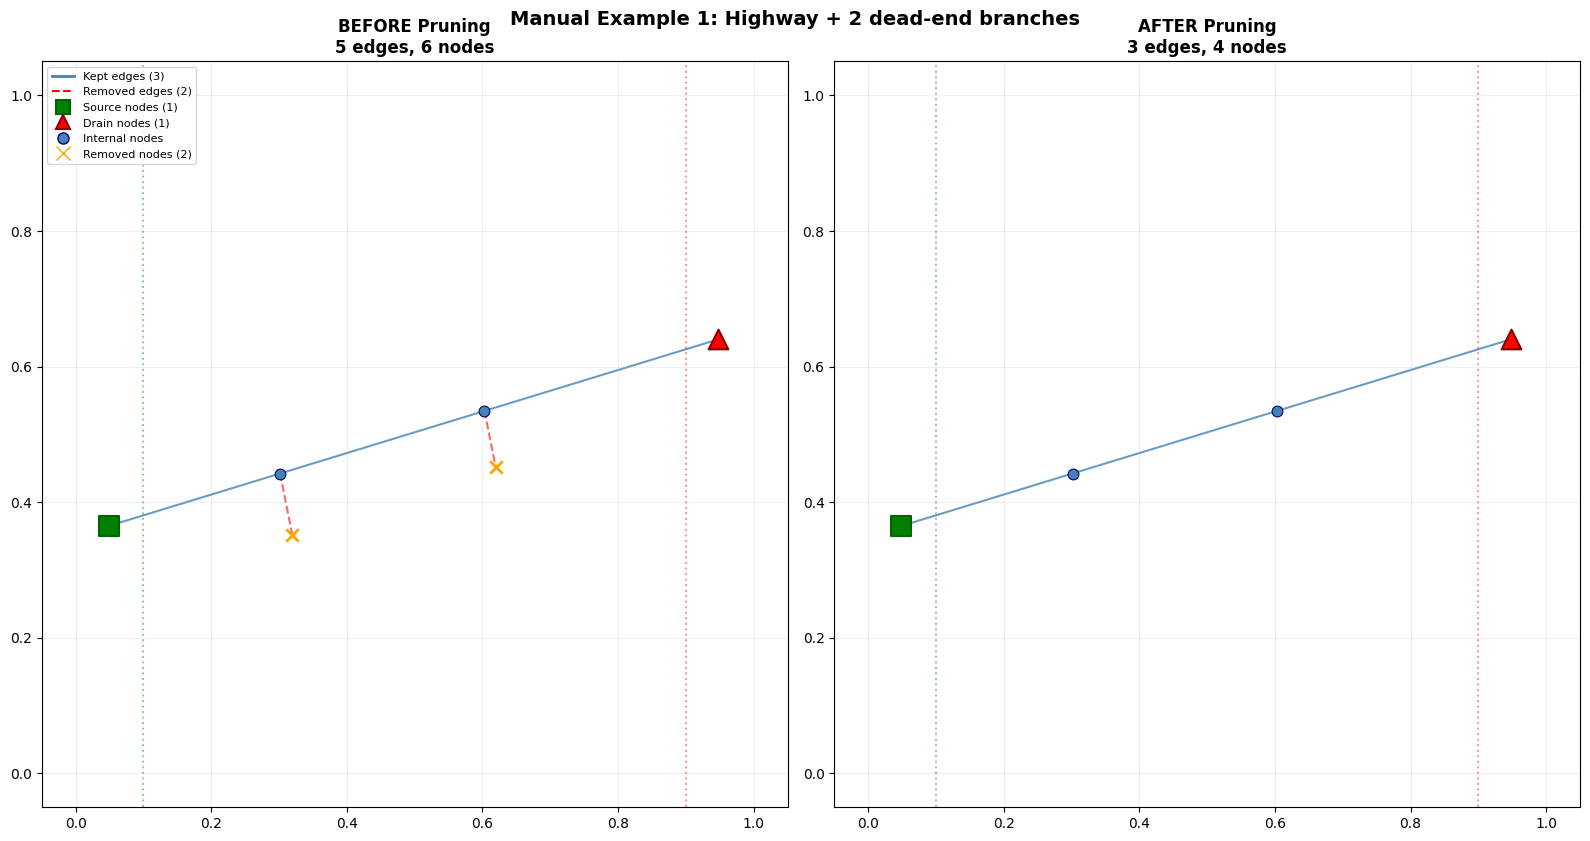

  Impedance (k=1000): 3000.0000 Ω, cond(M)=3.00e+00
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 771
  Timestamp: 20260707_154133
  Results directory: <project_root>/utils/../experiments/exp_771



  [OK] Figure saved: 04_before_after_pruning_N7.png
  [OK] JSON saved: network_data.json
  [OK] JSON saved: all_intersections.json
  [OK] JSON saved: lines_generated.json
  [OK] JSON saved: segment_edge_list_original.json
  [OK] JSON saved: segment_edge_list_pruned.json
  [OK] JSON saved: experiment_summary.json

Generating PDFs...


  [OK] Individual PDF saved: <project_root>/utils/../experiments/exp_771/experiment_771_report.pdf
  [WARNING] PDF auto-generation failed: Expecting value: line 9 column 21 (char 190)
  [saved] Experiment 771 → <project_root>/utils/../experiments/exp_771


In [5]:
results_ex1 = run_full_pipeline(
    points_1_ex1, points_2_ex1, angles_ex1, N_ex1, a_ex1,
    title="Manual Example 1: Highway + 2 dead-end branches",
    save=True,
)


### Example 2: Two diagonal rails + source/drain connectors + 2 dead-end branches

```
  (top rail S0) ─────────────────────────────────
                 ↑                      ↑
                SRC x≈0.05            DRN x≈0.93
                 ↓                      ↓
  (bot rail S1) ─────────────────────────────────

  Dead end off top rail: S4∩S0 ← S4 ← S4∩S5 (leaf)
  Dead end off bot rail: S6∩S1 ← S6 ← S6∩S7 (leaf)
```

- **S0** (top rail): gentle ↗ from (0,0.65) to (0.98,0.75).
- **S1** (bot rail): gentle ↘ from (0,0.35) to (0.98,0.25).
- **S2** (source connector): vertical at x=0.05, crosses both rails → 2 SOURCE nodes.
- **S3** (drain connector): vertical at x=0.93, crosses both rails → 2 DRAIN nodes.
- **S4** (top dead-end a): steep ↘ crossing S0 and S5.
- **S5** (top aux): gentle crossing S4 only → top dead-end leaf.
- **S6** (bot dead-end a): steep ↗ crossing S1 and S7.
- **S7** (bot aux): gentle crossing S6 only → bottom dead-end leaf.

Pruning removes 2 leaves (one per rail).

In [6]:
# ═══════════════════════════════════════════════════════════════════════
# MANUAL EXAMPLE 2: Two rails + shared source/drain connectors + 2 dead-ends
# ═══════════════════════════════════════════════════════════════════════
#
# S0 (top rail)    : gentle ↗ (θ≈+5.8°)
# S1 (bot rail)    : gentle ↘ (θ≈-5.8°)
# S2 (source conn) : vertical at x=0.05 → crosses S0 (SOURCE) and S1 (SOURCE)
# S3 (drain conn)  : vertical at x=0.93 → crosses S0 (DRAIN)  and S1 (DRAIN)
# S4 (top dead-a)  : steep ↘ crossing top rail S0 and S5
# S5 (top aux)     : gentle crossing S4 only → dead-end leaf (above top rail)
# S6 (bot dead-a)  : steep ↗ crossing bot rail S1 and S7
# S7 (bot aux)     : gentle crossing S6 only → dead-end leaf (below bot rail)

points_1_ex2 = [
    (0.00, 0.65),  # S0 top rail
    (0.00, 0.35),  # S1 bot rail
    (0.05, 0.20),  # S2 source connector (vertical)
    (0.93, 0.20),  # S3 drain  connector (vertical)
    (0.30, 0.85),  # S4 top dead-end a
    (0.20, 0.78),  # S5 top auxiliary (crosses S4 only)
    (0.55, 0.15),  # S6 bot dead-end a
    (0.50, 0.22),  # S7 bot auxiliary (crosses S6 only)
]
points_2_ex2 = [
    (0.98, 0.75),  # S0 end
    (0.98, 0.25),  # S1 end
    (0.05, 0.80),  # S2 end  (vertical at x=0.05)
    (0.93, 0.80),  # S3 end  (vertical at x=0.93)
    (0.40, 0.55),  # S4 end  (steep ↘, crosses S0 and S5)
    (0.45, 0.72),  # S5 end  (gentle, crosses S4 only)
    (0.65, 0.45),  # S6 end  (steep ↗, crosses S1 and S7)
    (0.75, 0.15),  # S7 end  (gentle, crosses S6 only)
]

angles_ex2 = calculate_angles(points_1_ex2, points_2_ex2)
N_ex2 = len(points_1_ex2)
a_ex2 = max(
    math.dist(points_1_ex2[i], points_2_ex2[i])
    for i in range(N_ex2)
)

print(f"Manual Example 2: {N_ex2} sticks, a_max = {a_ex2:.4f}")
for i in range(N_ex2):
    L = math.dist(points_1_ex2[i], points_2_ex2[i])
    print(f"  S{i}: {points_1_ex2[i]} → {points_2_ex2[i]},  L={L:.4f},  θ={math.degrees(angles_ex2[i]):.1f}°")


Manual Example 2: 8 sticks, a_max = 0.9851
  S0: (0.0, 0.65) → (0.98, 0.75),  L=0.9851,  θ=5.8°
  S1: (0.0, 0.35) → (0.98, 0.25),  L=0.9851,  θ=-5.8°
  S2: (0.05, 0.2) → (0.05, 0.8),  L=0.6000,  θ=90.0°
  S3: (0.93, 0.2) → (0.93, 0.8),  L=0.6000,  θ=90.0°
  S4: (0.3, 0.85) → (0.4, 0.55),  L=0.3162,  θ=-71.6°
  S5: (0.2, 0.78) → (0.45, 0.72),  L=0.2571,  θ=-13.5°
  S6: (0.55, 0.15) → (0.65, 0.45),  L=0.3162,  θ=71.6°
  S7: (0.5, 0.22) → (0.75, 0.15),  L=0.2596,  θ=-15.6°



  Manual Example 2: Two rails + 2 dead-ends (one per rail)
  Sticks: 8, Aspect ratio: 0.98508882848198
  Intersections found: 8
  Source nodes (x<0.1): 2
  Drain nodes (x>0.9): 2
  Percolating paths: 1
  Edges before pruning: 8
  Dead ends found: True (2 dangling segments)
  Iteration 1.1: removing 2 dead-end node(s) = 2 edge(s)
    → Dead-end nodes: [6 (0.334,0.748), 7 (0.567,0.201)...]
    → Remaining edges: 6

  ✓ Pruning complete: 2 node(s) and 2 edge(s) removed across 1 outer iteration(s).
  ✓ Verified: No internal dead-ends remain.
  Edges after pruning:  6
  Removed nodes (2): [6, 7]
  Removed edges (2): [(2, 6), (5, 7)]
  Still percolates after pruning: True


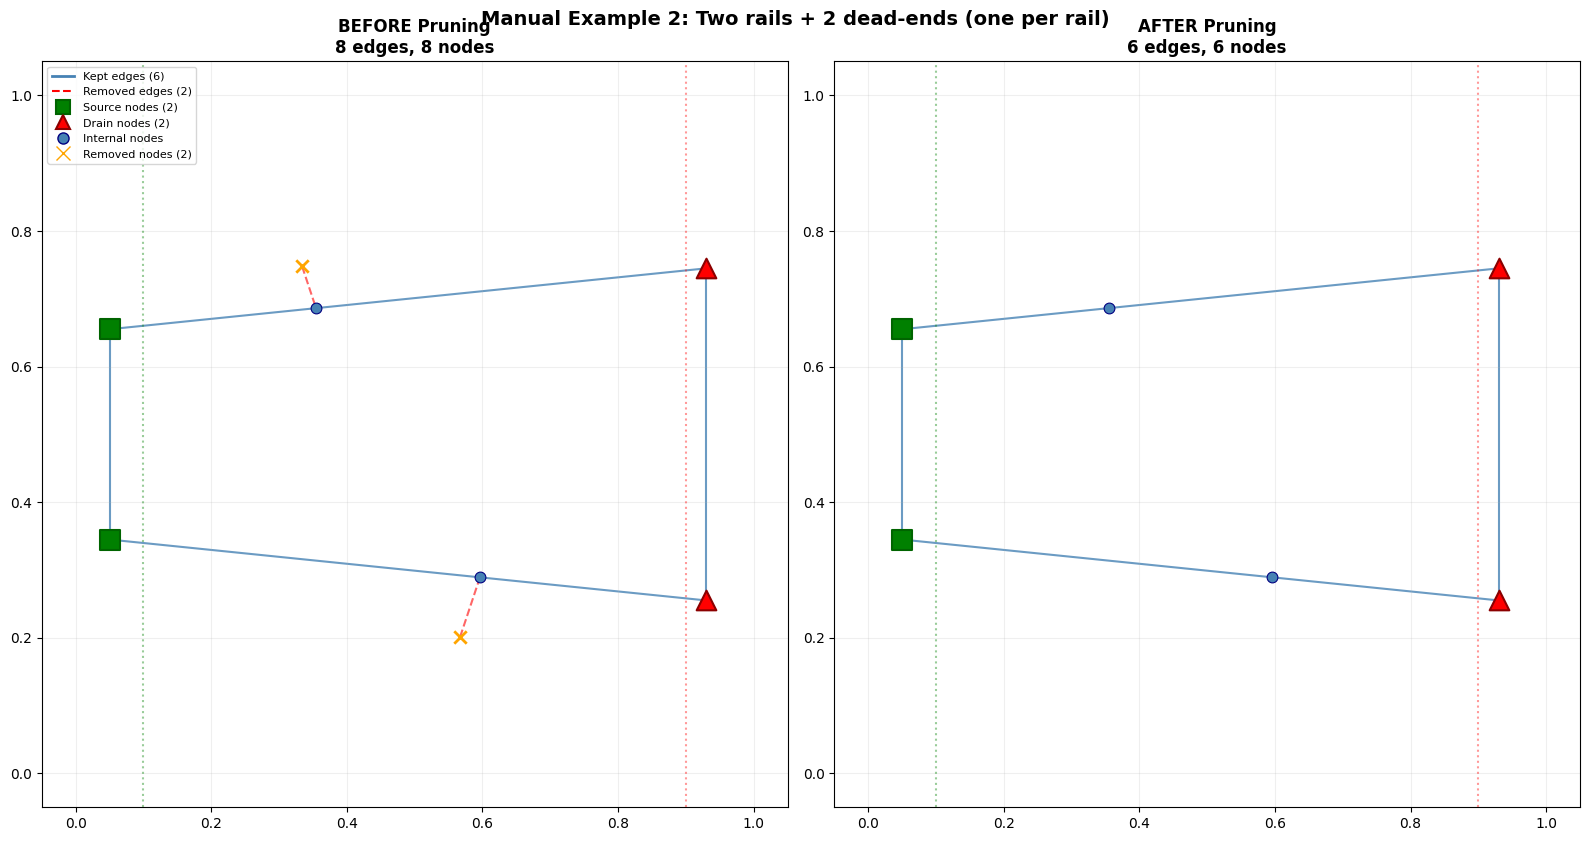

  Impedance (k=1000): 1000.0000 Ω, cond(M)=1.00e+00
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 772
  Timestamp: 20260707_154133
  Results directory: <project_root>/utils/../experiments/exp_772



  [OK] Figure saved: 04_before_after_pruning_N8.png
  [OK] JSON saved: network_data.json
  [OK] JSON saved: all_intersections.json
  [OK] JSON saved: lines_generated.json
  [OK] JSON saved: segment_edge_list_original.json
  [OK] JSON saved: segment_edge_list_pruned.json
  [OK] JSON saved: experiment_summary.json

Generating PDFs...


  [OK] Individual PDF saved: <project_root>/utils/../experiments/exp_772/experiment_772_report.pdf


  [WARNING] PDF auto-generation failed: Expecting value: line 9 column 21 (char 190)
  [saved] Experiment 772 → <project_root>/utils/../experiments/exp_772


In [7]:
results_ex2 = run_full_pipeline(
    points_1_ex2, points_2_ex2, angles_ex2, N_ex2, a_ex2,
    title="Manual Example 2: Two rails + 2 dead-ends (one per rail)",
    save=True,
)


### Example 3: Highway + 2-level cascading dead-end chain

```
  SOURCE──S0──[S3∩S0]──S0──DRAIN
                 |
                S3         (chain level 0)
                 |
              [S3∩S4]      (node B)
                 |
                S4         (chain level 1)
                 |
              [S4∩S5]      (node C – deepest dead-end leaf)
```

- **S0** (highway): gentle diagonal from source to drain.
- **S1** (source bus): nearly vertical at x≈0.05, crosses S0 → SOURCE node.
- **S2** (drain bus): nearly vertical at x≈0.93, crosses S0 → DRAIN node.
- **S3** (chain C0): steep stick crossing S0 (node A) and S4 (node B).
- **S4** (chain C1): gentle stick crossing S3 (node B) and S5 (node C).
- **S5** (chain C2): short stick crossing S4 (node C) only.

Cascading pruning:
1. node C (degree 1) → remove edge B–C (from S4),
2. node B (degree 1) → remove edge A–B (from S3).

Result: pure highway from SOURCE to DRAIN.

In [8]:
# ═══════════════════════════════════════════════════════════════════════
# MANUAL EXAMPLE 3: Highway + 2-level cascading dead-end chain
# ═══════════════════════════════════════════════════════════════════════
#
#   SOURCE──S0──[S3∩S0]──S0──DRAIN
#                  |  (node A)
#                 S3
#                  |  (node B = S3∩S4)
#                 S4
#                  |  (node C = S4∩S5)  ← deepest dead-end
#                 S5 (isolated leaf)
#
# Cascading prune:
#   1st iter : node C (degree 1) → prune edge B-C from S4
#   2nd iter : node B (degree 1) → prune edge A-B from S3
# Result    : pure highway SOURCE→DRAIN

points_1_ex3 = [
    (0.00, 0.40),  # S0 highway
    (0.04, 0.10),  # S1 source bus
    (0.92, 0.10),  # S2 drain  bus
    (0.30, 0.90),  # S3 chain C0  (crosses S0 at node A, and S4 at node B)
    (0.20, 0.80),  # S4 chain C1  (crosses S3 at node B, and S5 at node C)
    (0.40, 0.55),  # S5 chain C2  (crosses S4 at node C only)
]
points_2_ex3 = [
    (0.98, 0.60),  # S0 end
    (0.06, 0.70),  # S1 end
    (0.94, 0.70),  # S2 end
    (0.35, 0.40),  # S3 end
    (0.40, 0.60),  # S4 end
    (0.35, 0.80),  # S5 end
]

angles_ex3 = calculate_angles(points_1_ex3, points_2_ex3)
N_ex3 = len(points_1_ex3)
a_ex3 = max(
    math.dist(points_1_ex3[i], points_2_ex3[i])
    for i in range(N_ex3)
)

print(f"Manual Example 3: {N_ex3} sticks, a_max = {a_ex3:.4f}")
for i in range(N_ex3):
    L = math.dist(points_1_ex3[i], points_2_ex3[i])
    print(f"  S{i}: {points_1_ex3[i]} → {points_2_ex3[i]},  L={L:.4f},  θ={math.degrees(angles_ex3[i]):.1f}°")


Manual Example 3: 6 sticks, a_max = 1.0002
  S0: (0.0, 0.4) → (0.98, 0.6),  L=1.0002,  θ=11.5°
  S1: (0.04, 0.1) → (0.06, 0.7),  L=0.6003,  θ=88.1°
  S2: (0.92, 0.1) → (0.94, 0.7),  L=0.6003,  θ=88.1°
  S3: (0.3, 0.9) → (0.35, 0.4),  L=0.5025,  θ=-84.3°
  S4: (0.2, 0.8) → (0.4, 0.6),  L=0.2828,  θ=-45.0°
  S5: (0.4, 0.55) → (0.35, 0.8),  L=0.2550,  θ=101.3°



  Manual Example 3: Highway + 2-level cascading dead-end
  Sticks: 6, Aspect ratio: 1.0001999800039991
  Intersections found: 5
  Source nodes (x<0.1): 1
  Drain nodes (x>0.9): 1
  Percolating paths: 1
  Edges before pruning: 4
  Dead ends found: True (1 dangling segments)
  Iteration 1.1: removing 1 dead-end node(s) = 1 edge(s)
    → Dead-end nodes: [4 (0.388,0.612)...]
    → Remaining edges: 3
  Iteration 1.2: removing 1 dead-end node(s) = 1 edge(s)
    → Dead-end nodes: [3 (0.322,0.678)...]
    → Remaining edges: 2

  ✓ Pruning complete: 2 node(s) and 2 edge(s) removed across 1 outer iteration(s).
  ✓ Verified: No internal dead-ends remain.
  Edges after pruning:  2
  Removed nodes (2): [3, 4]
  Removed edges (2): [(2, 3), (3, 4)]
  Still percolates after pruning: True


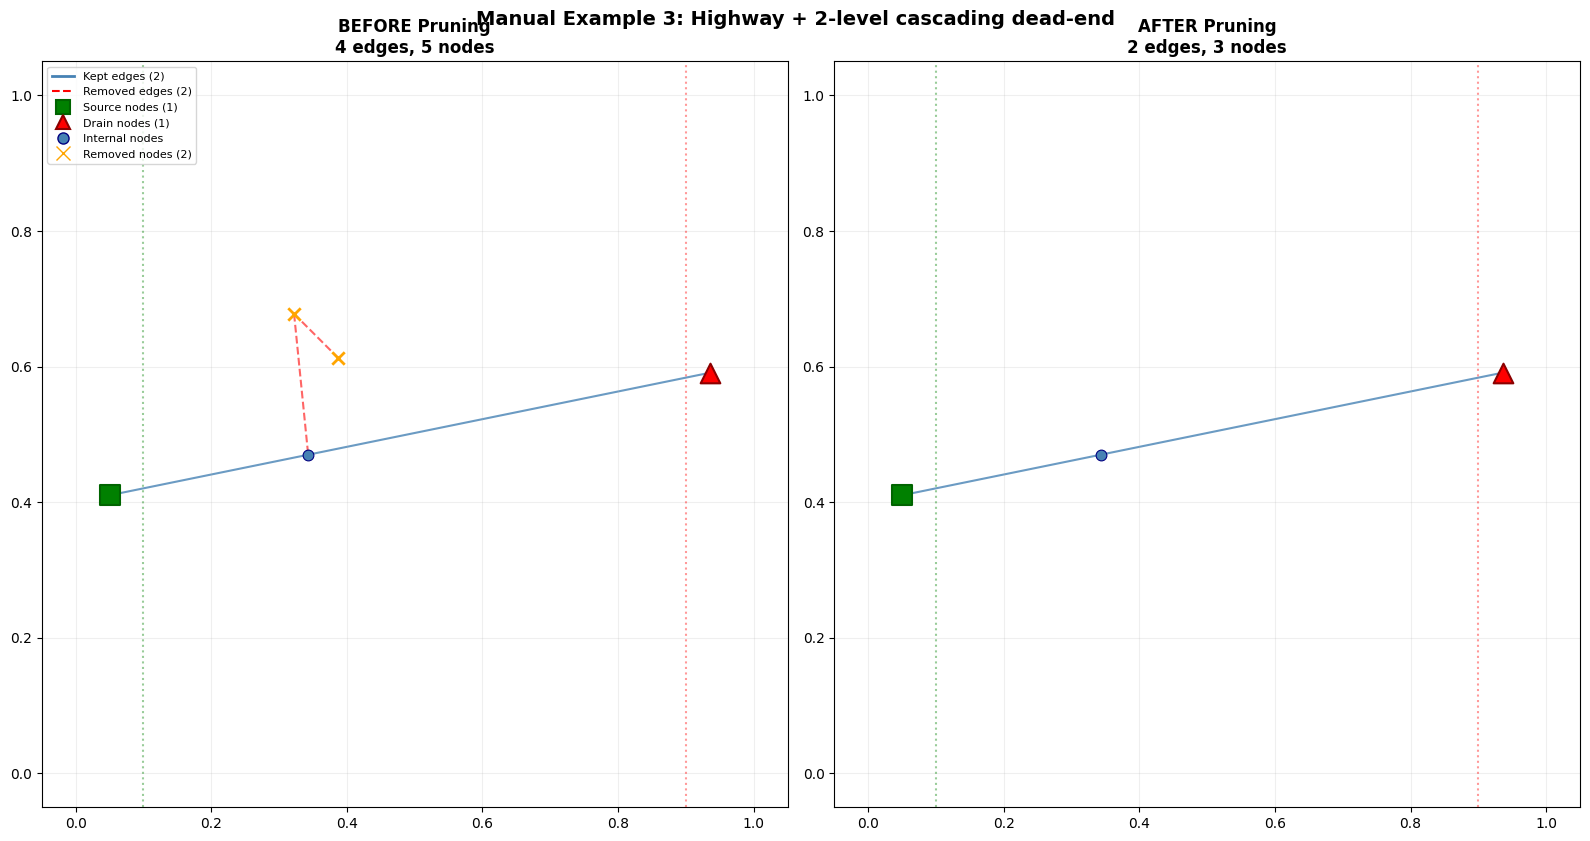

  Impedance (k=1000): 2000.0000 Ω, cond(M)=1.00e+00
EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 773
  Timestamp: 20260707_154134
  Results directory: <project_root>/utils/../experiments/exp_773



  [OK] Figure saved: 04_before_after_pruning_N6.png
  [OK] JSON saved: network_data.json
  [OK] JSON saved: all_intersections.json
  [OK] JSON saved: lines_generated.json
  [OK] JSON saved: segment_edge_list_original.json
  [OK] JSON saved: segment_edge_list_pruned.json
  [OK] JSON saved: experiment_summary.json

Generating PDFs...


  [OK] Individual PDF saved: <project_root>/utils/../experiments/exp_773/experiment_773_report.pdf


  [WARNING] PDF auto-generation failed: Expecting value: line 9 column 21 (char 190)
  [saved] Experiment 773 → <project_root>/utils/../experiments/exp_773


In [9]:
results_ex3 = run_full_pipeline(
    points_1_ex3, points_2_ex3, angles_ex3, N_ex3, a_ex3,
    title="Manual Example 3: Highway + 2-level cascading dead-end",
    save=True,
)


---
## 3. Augmented Networks

Load a previously generated network and manually add extra sticks that
create dead-end branches. This lets us test pruning on realistic random
networks that have been deliberately made to have dead ends.

**Set `LOAD_EXP` below to a valid experiment number that has `network_data.json`.**

In [10]:
# ═══════════════════════════════════════════════════════════════════════
# LOAD A PREVIOUS EXPERIMENT AND ADD DEAD-END STICKS
# ═══════════════════════════════════════════════════════════════════════
LOAD_EXP = None  # <-- Set to an experiment number, e.g. 5

if LOAD_EXP is not None:
    loaded = load_network(LOAD_EXP)
    pts1_aug = list(loaded["points_1"])
    pts2_aug = list(loaded["points_2"])
    ang_aug = list(loaded["angles"])
    a_aug = loaded["a"]
    N_orig = loaded["N"]

    # ── Add dead-end sticks ──
    # These sticks cross the existing network near the middle but lead nowhere.
    extra_sticks = [
        # A vertical stick in the middle of the domain
        ((0.50, 0.80), (0.50, 0.40)),
        # A diagonal going from mid-area toward bottom-right (dead end)
        ((0.50, 0.45), (0.65, 0.15)),
        # Another dangling stick near the middle
        ((0.40, 0.60), (0.30, 0.85)),
    ]

    for (p1, p2) in extra_sticks:
        pts1_aug.append(p1)
        pts2_aug.append(p2)
        ang_aug.append(math.atan2(p2[1] - p1[1], p2[0] - p1[0]))

    N_aug = len(pts1_aug)
    # Recompute a_max to account for new sticks
    a_aug = max(math.dist(pts1_aug[i], pts2_aug[i]) for i in range(N_aug))

    print(f"Original network: {N_orig} sticks from experiment {LOAD_EXP}")
    print(f"Added {len(extra_sticks)} dead-end sticks")
    print(f"Augmented network: {N_aug} sticks, a_max = {a_aug:.4f}")
else:
    print("Set LOAD_EXP to an experiment number to test augmented networks.")
    print("Skipping this section.")

Set LOAD_EXP to an experiment number to test augmented networks.
Skipping this section.


In [11]:
if LOAD_EXP is not None:
    results_aug = run_full_pipeline(
        pts1_aug, pts2_aug, ang_aug, N_aug, a_aug,
        title=f"Augmented Network (exp_{LOAD_EXP} + {len(extra_sticks)} dead-end sticks)",
        save=True,
    )
else:
    print("Skipped — set LOAD_EXP above.")

Skipped — set LOAD_EXP above.


---
## 4. Small-`a` Random Networks

Shorter sticks create denser intersection patterns. With many short sticks,
the percolating component is more likely to have side branches and dead ends
that `find_path` includes in its BFS tree but that don't connect source to drain.

We generate several random networks with small `a` and high `N`, then
run the full pipeline on each. Networks that don't percolate are skipped.

  No percolating path found.
  [0.25, N=80] NoPerc | NoDead | Edges: 0->0 (removed 0) | R=-
  Boundary conditions not met. No percolation possible.
  [0.3, N=60] NoPerc | NoDead | Edges: 0->0 (removed 0) | R=-


  No percolating path found.
  [0.2, N=120] NoPerc | NoDead | Edges: 0->0 (removed 0) | R=-
  Boundary conditions not met. No percolation possible.
  [0.35, N=50] NoPerc | NoDead | Edges: 0->0 (removed 0) | R=-


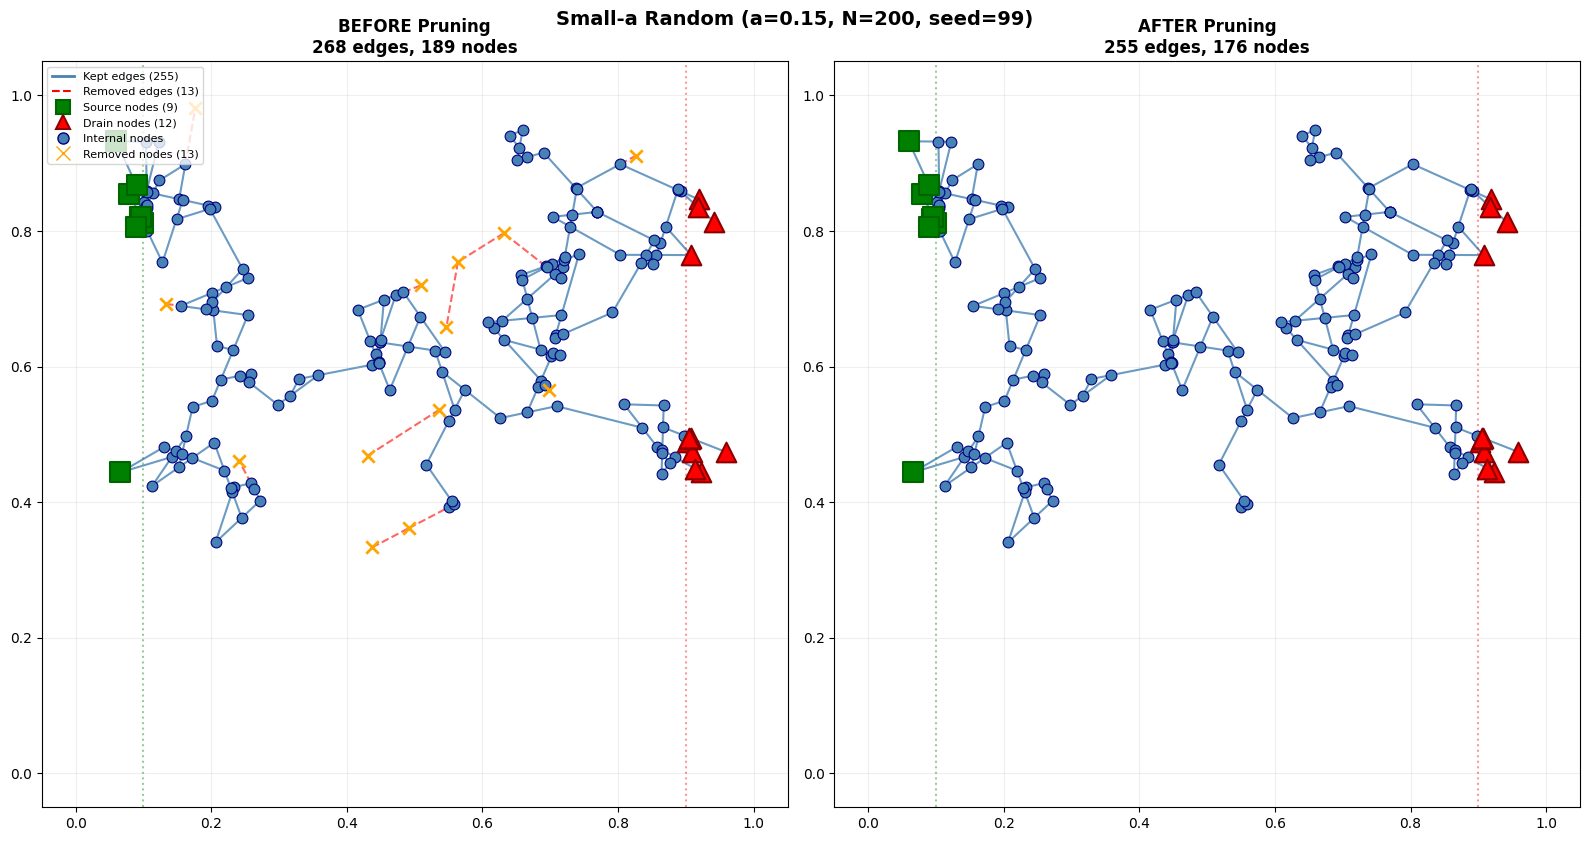

<project_root>/utils/impedance_calculator.py:439: RuntimeWarning: divide by zero encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:439: RuntimeWarning: overflow encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:439: RuntimeWarning: invalid value encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/impedance_calculator.py:543: RuntimeWarning: divide by zero encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:543: RuntimeWarning: overflow encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:543: RuntimeWarning: invalid value encountered in matmul
  voltage_drops = -A @ V_full  # Voltage drop across each edge
<project_root>/utils/impedance_calculator.py:544: RuntimeWarning: divide by zero encountered in matmul
  I = G_matrix @ voltage_drop

EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 774
  Timestamp: 20260707_154135
  Results directory: <project_root>/utils/../experiments/exp_774



  [OK] Figure saved: 04_before_after_pruning_N200.png
  [OK] JSON saved: network_data.json
  [OK] JSON saved: all_intersections.json
  [OK] JSON saved: lines_generated.json
  [OK] JSON saved: segment_edge_list_original.json
  [OK] JSON saved: segment_edge_list_pruned.json
  [OK] JSON saved: experiment_summary.json

Generating PDFs...
  [OK] Individual PDF saved: <project_root>/utils/../experiments/exp_774/experiment_774_report.pdf
  [WARNING] PDF auto-generation failed: Expecting value: line 9 column 21 (char 190)
  [0.15, N=200] Perc | DeadEnds | Edges: 268->255 (removed 13) | R=16087.84 cond=7.2e+02

  Done: 5 configs processed.


In [12]:
# ═══════════════════════════════════════════════════════════════════════
# GENERATE MULTIPLE SMALL-a RANDOM NETWORKS
# ═══════════════════════════════════════════════════════════════════════
small_a_configs = [
    {"a": 0.25, "N": 80,  "seed": 42},
    {"a": 0.30, "N": 60,  "seed": 123},
    {"a": 0.20, "N": 120, "seed": 7},
    {"a": 0.35, "N": 50,  "seed": 2024},
    {"a": 0.15, "N": 200, "seed": 99},
]

all_small_a_results = []

for cfg in small_a_configs:
    a_val = cfg["a"]
    N_val = cfg["N"]
    seed = cfg["seed"]

    np.random.seed(seed)

    pts1 = []
    pts2 = []
    angs = []

    try:
        generate_points(N_val, pts1, pts2, angs, a_val, enforce_bounds=True)
    except RuntimeError as e:
        print(f"  Skipping a={a_val}, N={N_val}: {e}")
        continue

    title = f"Small-a Random (a={a_val}, N={N_val}, seed={seed})"
    r = run_full_pipeline(pts1, pts2, angs, N_val, a_val, title=title, verbose=False, save=True)
    r["config"] = cfg
    all_small_a_results.append(r)

    # Compact summary line
    perc = "Perc" if r.get("has_percolation") else "NoPerc"
    dead = "DeadEnds" if r.get("has_dead_ends") else "NoDead"
    stats = r.get("pruning_stats", {})
    eb = len(stats.get("edges_before", []))
    ea = len(stats.get("edges_after", []))
    rem = len(stats.get("removed_edges", []))
    if "impedance" in r:
        singular_tag = " [SINGULAR]" if r.get("impedance_singular") else ""
        cond = r.get("condition_number")
        cond_str = f" cond={cond:.1e}" if cond is not None else ""
        imp = f"R={r['impedance']:.2f}{cond_str}{singular_tag}"
    else:
        imp = "R=-"
    print(f"  [{cfg['a']}, N={cfg['N']}] {perc} | {dead} | Edges: {eb}->{ea} (removed {rem}) | {imp}")

print(f"\n  Done: {len(all_small_a_results)} configs processed.")

In [13]:
# ═══════════════════════════════════════════════════════════════════════
# VISUALIZATION & SUMMARY: Small-a Networks
# ═══════════════════════════════════════════════════════════════════════

# ── 1. Small-a Network Summary Table ──
W = 115
print(f"\n{'='*W}")
print(f"{'SMALL-a NETWORK PRUNING SUMMARY':^{W}}")
print(f"{'='*W}")
print(f"{'a':>5} {'N':>4} {'seed':>5} {'Perc (pre)':>11} {'Perc (post)':>12} "
      f"{'Edges Before':>13} {'Edges After':>12} {'Removed':>8} "
      f"{'R (Ω)':>10} {'Singular?':>10} {'cond(M)':>12}")
print(f"{'-'*W}")

for r in all_small_a_results:
    cfg = r["config"]
    perc_pre  = "Yes" if r.get("has_percolation")      else "No"
    perc_post = "Yes" if r.get("proceed_to_impedance") else "No"
    edges_b = len(r["pruning_stats"]["edges_before"]) if "pruning_stats" in r else "-"
    edges_a = len(r["pruning_stats"]["edges_after"])  if "pruning_stats" in r else "-"
    removed = len(r["pruning_stats"]["removed_edges"]) if "pruning_stats" in r else "-"
    impedance = f"{r['impedance']:.2f}" if "impedance" in r else "-"
    singular  = "Yes" if r.get("impedance_singular") else ("No" if "impedance" in r else "-")
    cond = r.get("condition_number")
    cond_str = f"{cond:.2e}" if cond is not None else "-"
    print(f"{cfg['a']:>5.2f} {cfg['N']:>4d} {cfg['seed']:>5d} {perc_pre:>11} {perc_post:>12} "
          f"{str(edges_b):>13} {str(edges_a):>12} {str(removed):>8} "
          f"{impedance:>10} {singular:>10} {cond_str:>12}")

print(f"{'='*W}")


                                          SMALL-a NETWORK PRUNING SUMMARY                                          
    a    N  seed  Perc (pre)  Perc (post)  Edges Before  Edges After  Removed      R (Ω)  Singular?      cond(M)
-------------------------------------------------------------------------------------------------------------------
 0.25   80    42          No           No             -            -        -          -          -            -
 0.30   60   123          No           No             -            -        -          -          -            -
 0.20  120     7          No           No             -            -        -          -          -            -
 0.35   50  2024          No           No             -            -        -          -          -            -
 0.15  200    99         Yes          Yes           268          255       13   16087.84         No     7.21e+02


## Reloading a saved experiment

The cell below is commented out; it shows how to load a saved geometry and rerun it.

In [14]:
# # 1. Load the saved geometry from any experiment
# net = load_network(42)   # loads exp_42/

# # 2. You get back the original points
# points_1 = net["points_1"]
# points_2 = net["points_2"]
# angles    = net["angles"]
# N         = net["N"]
# a         = net["a"]

# # 3. Pass it to run_full_pipeline normally → replots everything
# results = run_full_pipeline(
#     points_1, points_2, angles, N, a,
#     title=f"Rerun exp_{42}",
#     save=False,  # or True to save it in a new folder
# )